In [2]:
import copy
import logging
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import random
import seaborn as sns


import config as cfg
from data_acquirer import get_data, gen_data
import helpers
import heuristic

from heuristic import Path, Solution
from problem_variables import Raw, Task, Processed

In [4]:
## Alain cut
from docplex.mp.model import Model



In [4]:
a =(200,400)
b = (700,500)
#distance from a to b
dist = np.sqrt((a[0]-b[0])**2 + (a[1]-b[1])**2)
dist

509.9019513592785

In [32]:
reverse_weight = 3
pred_a  =[5,1,3]
weight_pred_a = {5:3,3:2,1:4}
waiting_pred_a = {5:1.2,1:1.1, 3: 5.5}
# Create a dataframe that has 3 columns :waiting time, weight, and pred from the above data

def get_u(pred, weight_pred, waiting_pred,reverse_weight):
    df = pd.DataFrame(columns=['pred','waiting_time', 'weight', ])
    weights = []
    waitings = []
    for i in pred:
        weights.append(weight_pred[i])
        waitings.append(waiting_pred[i])
    df['waiting_time'] = waitings
    df['weight'] = weights
    df['pred'] = pred
    #Sort df by waiting_time in decreasing order and choose the preds such that the sum of their weights is larger than reverse_weight
    df = df.sort_values(by='waiting_time', ascending=False)
    sum_weight = 0
    chosen_preds = []
    i = 0
    for weight in df['weight']:
        while sum_weight < reverse_weight:
            sum_weight += weight
            i += 1
        chosen_preds = list(df['pred'][:i])
    return chosen_preds

get_u(pred_a, weight_pred_a, waiting_pred_a,reverse_weight)

[3, 5]

In [3]:
def get_critical_path(graph_sol: nx.DiGraph, c_travel, c_operate:dict):
    z,w = helpers.get_related_times(graph_sol, c_travel, c_operate)
    # Find the critical path of graph_sol(nx.DiGraph) and return the path, the start time of each task is in z[i] is the start time of task i,w[(i,j)] is the waiting time of task i to j
    # Get predessors of node -1 in graph_sol (the lastest task in the graph_sol)
    cur_task = -1
    cur_preds = list(graph_sol.predecessors(-1))
    critical_edges = []
    while cur_task !=0:
        for pred in cur_preds:
            cur_w  = w[(pred,-1)]
            if cur_w == 0:
                cur_task = pred
                critical_edges.append((pred,cur_task))
                break
    return critical_edges

## Tabu search

In [ ]:
class TabuSearch:
    def __init__(self, processed, c_travel, c_operate, init_solution_func = heuristic.VGeneralizedSolver):
        self.processed = processed
        self.c_travel = c_travel
        self.c_operate = c_operate
        self.init_solution_func = init_solution_func

    def set_init_func(self, init_solution_func):
        self.init_solution_func = init_solution_func

    def _get_fitness(self, solution):
        #TODO placeholder
        pass

    def _get_neighbors(self,solution):
        neighbors = []
        #TODO placeholder
        return neighbors
    
    def _get_reverse_neighbors(self,solution, num_neighbors):
        # This is N_reverse in the paper
        #TODO
        pass

    def _get_reroute_neighbors(self,solution, num_neighbors):
        # This is N_reroute in the paper
        #TODO
        pass

    def _path_to_edges(self, path : list):
        edges = []
        cur_len = len(path)
        if path[0] != 0:
            edges.append((0,path[0]))
        for i in range(cur_len - 1):
            edges.append((path[i],path[i + 1]))
        # edges.append((path[-1],-1))
        return edges

    def _paths_to_weighted_edges(self,paths: list): 
        """
        extract the edges to the directed graph G from a
        set of paths. More on section 2 in "Formal construct
        solution from paths 13-12-2023" document
        
        Parameters
        ----------
        paths : list
            list of tuples, every tuple is a path of every robot
            excluding the sink and the source (nessessary?)
            
        Returns
        -------
        edges : list
            list of weighted edges, every element has the form of (source, sink, weight) 
            
        """
        edges = []
        for path in paths:
            cur_edges = self._path_to_edges(path)
            edges += cur_edges
        # edges = dict((x,edges.count(x)) for x in set(edges))
        edges = [(edge[0],edge[1], edges.count(edge)) for edge in set(edges)]
        return edges
        


    def _to_graph(self, paths: list):
        """
        Return a networkx *weighted* graph from the set of paths.
        """
        G = nx.MultiGraph()
        weighted_edges = self._paths_to_weighted_edges(paths)
        G.add_weighted_edges_from(weighted_edges)
        return G

    
    def search(self,total_robots, init_sol, max_iters, tabu_list_size):
        #TODO placeholder
        init_sol = self.init_function.solve(
            cfg.TABU_TASK_EACH_ITERATION,
            cfg.TABU_CONSIDER_PROCESS_TIME
        )
        init_sol_makespan = init_sol.get_makespan()
        logging.info(f"Initial makespan: {init_sol_makespan}")
        idx_paths = init_sol.get_idx_paths(change_sink_idx = True)
        G = self._to_graph(idx_paths)
        
        best_solution = init_sol
        best_solution_fitness = self._get_fitness(best_solution)
        tabu_list = []
        tabu_list.append(best_solution)
        for i in range(max_iters):
            neighbors = self._get_neighbors(best_solution)
            best_neighbor = None
            best_neighbor_fitness = np.inf

            for neighbor in neighbors:
                if neighbor not in tabu_list: #find a way to check this quickly
                    neighbor_fitness = self._get_fitness(neighbor)
                    if best_neighbor is None or neighbor_fitness > best_neighbor_fitness:
                        best_neighbor = neighbor
                        best_neighbor_fitness = neighbor_fitness

            if best_neighbor is None:
                break
            if best_neighbor_fitness > best_solution_fitness:
                best_solution = best_neighbor
                best_neighbor_fitness = best_neighbor_fitness

            tabu_list.append(best_neighbor)
            if len(tabu_list) > tabu_list_size:
                tabu_list.pop(0)

        return best_solution


In [16]:
edges = [(1,2),(3,4),(1,2),(5,6)]
# edges = dict((x,edges.count(x)) for x in set(edges))
np.random.shuffle(edges)
edges

[(1, 2), (1, 2), (3, 4), (5, 6)]

In [11]:
edges

[(1, 2), (3, 4), (5, 6), (1, 2)]

In [44]:
import networkx as nx
weighted_edges = [(1,2,4),(2,3,6),(4,5,3),(4,2,4)]
G = nx.DiGraph()
G.add_weighted_edges_from(weighted_edges)

In [45]:
(a,b) = (1,2)
(c,d) = (4,5)
w1 = G[a][b]['weight']
w2 = G[c][d]['weight']
reroute_amount = min(w1,w2)
G[a][b]['weight'] -= reroute_amount
if G[a][b]['weight'] == 0:
    G.remove_edge(a,b)
G[c][d]['weight'] -= reroute_amount
if G[c][d]['weight'] == 0:
    G.remove_edge(c,d)
#check if edge (a,d)  exists
if G.has_edge(a,d):
    G[a][d]['weight'] += reroute_amount
else:
    G.add_edge(a,d,weight = reroute_amount)
if G.has_edge(c,b):
    G[c][b]['weight'] += reroute_amount
else:
    G.add_edge(c,b,weight = reroute_amount)


In [46]:
G.edges(data=True)

OutEdgeDataView([(1, 2, {'weight': 1}), (1, 5, {'weight': 3}), (2, 3, {'weight': 6}), (4, 2, {'weight': 7})])

In [47]:
neighbors = {
    'a':15,
    'b':16
}
for n in neighbors:
    print(n)

a
b


In [14]:
method = 5

total_robots = 10
random_data = False

data_type = 'csv'
# data_name = 'data2.csv'
# data_name = 'wr2/bar-n100-1-3.csv' #real data
data_name = 'lim/400/LC1_4_1-5-uniform.csv'  
# dist_path = 'wr2/bar-n100-1-dist.csv' #real data
total_tasks = 6 # random data

if False:
    is_depot_task = True
else:
    is_depot_task = False #TODO remove this
if random_data:
    raw = gen_data(total_robots, total_tasks, False, is_depot_task)
else:
    raw = get_data(data_name, data_type, is_depot_task)

print(f'Solving for {total_robots} robots and {len(raw.tasks)} tasks')

processed_h = heuristic.process_greedy_1(raw)
depot = processed_h.depot
tasks = processed_h.tasks
c_travel = helpers.create_task_dist_dict(depot,tasks)
c_operate = helpers.create_operate_dict(depot,tasks)


Solving for 10 robots and 211 tasks


In [12]:
solve_result_h_jp = heuristic.solve_greedy_jp_compare_start_time(processed_h, total_robots)
task_each_ite = 'random'
max_iter = 100
cur_best = 10**6
task_range = [1,4]
i= 0

while i <max_iter:
    solve_viet = heuristic.VGeneralizedSolver(processed_h,c_travel, c_operate)
    sol = solve_viet.solve(total_robots,task_each_ite, False, task_range = task_range)
    makespan = sol.get_makespan()
    if makespan < cur_best:
        cur_best = makespan
    i += 1

print(f'Viet Generalized best makespan: {cur_best}')

JP heuristics sol is 935.59
Viet generalized sol is 1120.93
Viet generalized sol is 1057.31
Viet generalized sol is 1070.18
Viet generalized sol is 1042.61
Viet generalized sol is 932.58
Viet generalized sol is 1038.13
Viet generalized sol is 958.34
Viet generalized sol is 896.56
Viet generalized sol is 1034.92
Viet generalized sol is 1046.49
Viet generalized sol is 975.49
Viet generalized sol is 966.88
Viet generalized sol is 981.26
Viet generalized sol is 976.39
Viet generalized sol is 949.2
Viet generalized sol is 1053.61
Viet generalized sol is 1029.01
Viet generalized sol is 1010.93
Viet generalized sol is 950.97
Viet generalized sol is 988.2
Viet generalized sol is 1094.2
Viet generalized sol is 1107.64
Viet generalized sol is 1059.2
Viet generalized sol is 875.71
Viet generalized sol is 938.88
Viet generalized sol is 934.35
Viet generalized sol is 938.18
Viet generalized sol is 1028.27
Viet generalized sol is 1063.83
Viet generalized sol is 1144.2
Viet generalized sol is 1027.05

In [7]:
sol.get_makespan()

1068.720492425073

In [8]:
paths = [[0, 1, 0],[0, 1, 0],[0, 3, 2, 0]]

In [3]:

# L = {6:{'p1':24,'p2':25,'p3':14,'p4':18},5:{'p1':19,'p2':10,'p3':17,'p4':18},7:{'p1':14,'p2':16,'p3':12,'p4':20}}
L = {6:{'p1':24,'p2':25,'p3':14,'p4':18},5:{'p1':19,'p2':17,'p3':11,'p4':18},7:{'p1':14,'p2':16,'p3':12,'p4':20}}
#task 6 need 2 robots, task 5 need 2 robots, task 7 need 1 robots
L_list = [(task_idx,path,cost) for task_idx in L for path,cost in L[task_idx].items()]
L_list
# Create a dataframe from L_list
df_L = pd.DataFrame(L_list, columns = ['task_idx', 'path', 'cost']).sort_values('cost')
df_L

,task_idx,path,cost
6,5,p3,11
10,7,p3,12
2,6,p3,14
8,7,p1,14
9,7,p2,16
5,5,p2,17
3,6,p4,18
7,5,p4,18
4,5,p1,19
11,7,p4,20


In [21]:
solve_result_h_jp = heuristic.solve_greedy_jp_compare_start_time(processed_h, total_robots)
solve_result_h_jp.get_makespan()

JP heuristics sol is 375.68


375.6818752141112

In [24]:
task_each_ite = 1
solve_viet = heuristic.VGeneralizedSolver(processed_h,c_travel, c_operate)
sol_viet = solve_viet.solve(total_robots,task_each_ite, False)

JP heuristics sol is 425.41


In [40]:
for path in solve_result_h_jp.paths:
    print(f'{path} takes {path.total_time}s')

Path [0, 11, 13, 24, 25, 27, 28, 26, 17, 19, 21, 20, 18, 7, 10, 8, 39, 30, 32, 31, 0] takes 375.6818752141112s
Path [0, 11, 16, 5, 3, 1, 52, 51, 50, 46, 45, 44, 41, 43, 38, 0] takes 361.68016030494437s
Path [0, 11, 15, 6, 5, 3, 1, 52, 49, 53, 50, 46, 45, 44, 41, 43, 38, 0] takes 361.68016030494437s
Path [0, 11, 15, 6, 5, 2, 1, 52, 53, 50, 46, 45, 44, 42, 43, 38, 0] takes 361.68016030494437s
Path [0, 11, 15, 6, 5, 2, 1, 48, 47, 50, 46, 45, 44, 40, 43, 38, 0] takes 361.68016030494437s
Path [0, 37, 33, 23, 25, 27, 28, 26, 17, 19, 21, 20, 18, 7, 10, 8, 39, 30, 32, 31, 0] takes 375.6818752141112s
Path [0, 36, 35, 33, 23, 25, 27, 28, 26, 17, 19, 20, 18, 7, 10, 8, 39, 29, 32, 31, 0] takes 375.6818752141112s
Path [0, 36, 35, 33, 25, 27, 26, 17, 19, 20, 9, 7, 10, 8, 39, 29, 31, 0] takes 375.6818752141112s
Path [0, 36, 34, 22, 24, 25, 28, 17, 21, 20, 9, 10, 39, 29, 31, 0] takes 375.6818752141112s
Path [0, 12, 14, 4, 5, 2, 1, 48, 50, 7, 8, 43, 38, 0] takes 361.68016030494437s


In [6]:
class Path:
    def __init__(self,depot):
        self.tasks =[depot]
        self.total_time = 0
        self.travel_time = 0
        pass
    
    def insert(self, task):
        self.tasks.append(task)
        self.update_travel_time(task)
        return
    
    def update_total_time(self, time):
        self.total_time = time
        return
    
    def update_travel_time(self,task):
        last_task = self.get_last_task()
        self.travel_time += helpers.cal_dist_task(last_task, task)
#         return travel_time
    
    def get_insert_cost(self, task, c_travel, c_operate):
        last_task = self.get_last_task()
        cost_if_insert = self.total_time + c_travel[last_task.index][task.index] + c_operate[task.index]
        return cost_if_insert
    
    def get_last_task(self):
        return self.tasks[-1]
    
    def __repr__(self):
            return f"Path {[task.index for task in self.tasks]}"

In [7]:
class Solution:
    def __init__(self, paths, depot, tasks):
        self.paths = paths
        self.depot = depot
        self.tasks = tasks
        
    def __repr__(self):
        return f"Paths {self.paths}"

In [8]:
is_depot_task = True
if random_data:
    raw = gen_data(total_robots, total_tasks, False, is_depot_task)
else:
    raw = get_data(data_name,'csv', is_depot_task)

c_travel = helpers.create_task_dist_dict(raw.depot,raw.tasks)
c_operate = helpers.create_operate_dict(raw.depot,raw.tasks)
for i in range(len(c_travel)):
    c_travel[i].pop(i)

In [9]:


uninserted = copy.deepcopy(raw.tasks) #j left
paths = [Path(raw.depot) for _ in range(total_robots)]
cur_sol = Solution(paths,raw.depot, raw.tasks)
best_obj = 0

idx_task_mapper = {task.index: task for task in raw.tasks}

C_max = 0
while len(uninserted) > 0:
    shortest_path_length = 9_999_999
    for path in cur_sol.paths:
        last_task = path.get_last_task()
        last_path_idx = last_task.index
        closest_idx = min(c_travel[last_path_idx],key = c_travel[last_path_idx].get)
        closest_task = idx_task_mapper[closest_idx]
        cost_if_insert = path.get_insert_cost(closest_task,c_travel,c_operate)
#         delta  = cost_if_insert - C_max
    
        if cost_if_insert < shortest_path_length:
            shortest_path_length = cost_if_insert
            best_path = path
            best_task = idx_task_mapper[closest_idx]
    
    print(f"BEST PATH: {best_path} \n BEST TASK: {best_task}")
    costs_if_insert = {path: path.get_insert_cost(best_task,c_travel, c_operate)}
#     print(f'c_travel {c_travel}')
    sorted_cost = list(np.sort(list(costs_if_insert.values())))
    shortest_to_insert_costs = sorted_cost[:best_task.n]
    inserted_paths_length = shortest_to_insert_costs[-1]
    for _ in range(best_task.n):
        cur_length = shortest_to_insert_costs.pop()
        for path, length in costs_if_insert.items():
            if length == cur_length:
                path.insert(best_task)
                path.update_total_time(inserted_paths_length)
                
    for i in range(len(c_travel)):
        try:
            c_travel[i].pop(best_task.index)
        except:
            pass
    
    uninserted.pop(best_task)
    # Remember to remove best_task from c_travel

BEST PATH: Path [0] 
 BEST TASK: Task 1,[  0 100],[  0 100],1


TypeError: 'Task' object cannot be interpreted as an integer

In [ ]:
def insert_single(solution, task):
    """
    Find a best spot to insert the `task` into `solution`
    
    Parameters
    ----------
    solution: Solution
    current solution
    task : Task
    current task want to insert to the solution, note that this must be a single task.
    """
    for path in solution.paths: 
        for i in range(len(path)):
            temp_path = path.insert(i,task)
            

## Construct solution from paths

In [2]:
def paths_to_edges(paths: list): 
    """
    extract the edges to the directed graph G from a
    set of paths. More on section 2 in "Formal construct
    solution from paths 13-12-2023" document
    
    Parameters
    ----------
    paths : list
        list of tuples, every tuple is a path of every robot
        excluding the sink and the source (nessessary?)
           
    Returns
    -------
    edges : list
        list of edges, note that there may be duplications edges
        
    """
    edges = []
    for path in paths:
        # cur_len = len(path)
        # edges.append((0,path[0]))
        # for i in range(cur_len-1):
        #     edges.append((path[i],path[i+1]))
        # edges.append((path[-1],-1))
        cur_edges = path_to_edges(path)
        edges += cur_edges
    return edges

def path_to_edges(path : list):
    edges = []
    cur_len = len(path)
    edges.append((0,path[0]))
    for i in range(cur_len - 1):
        edges.append((path[i],path[i + 1]))
    edges.append((path[-1],-1))
    return edges

In [3]:
def get_out_nodes(graph: nx.DiGraph):
    """
    Get a dictionary of out node from all nodes on a directed graph
    
    Parameters
    ----------
    graph : nx.DiGraph


    Returns
    -------
    out_nodes : dict
        `outnodes[1] = [2,3,69]` means that edges (1,2), (1,3), (1,69) in the graph.
    """
    out_nodes = {}
    nodes = list(graph.nodes())
    for node in nodes:
        out_nodes[node] = list(graph.successors(node))

    return out_nodes

In [4]:
def check_tasks_appearance(paths,raw):
    """
    Check if every tasks j exists in exact n_j paths
    """
    appearances = {task.index:0 for task in raw.tasks} # list of task: appearance
    for path in paths:
        len_path = len(path)
        for i in range(len_path):
            cur_idx = path[i]
            appearances[cur_idx] +=1
    
    appearances_correct = True
    for task in raw.tasks:
        n = task.n
        task_idx = task.index
        if n!= appearances[task_idx]:
            appearances_correct = False
            print(f"Task {task_idx} appears in {appearances[task_idx]} paths instead of {n}")
            break
        
    return appearances_correct

In [5]:
def paths_to_sol(paths, c_travel, c_operates, obj= "makespan"):
    """
    Construct solution from paths, consists of starting time
    of everynode and the makespan
    
    Parameters
    ----------
    paths : list
        see function `paths_to_edges()`
    c_travel : dict
        c_travel[0][4] is c_04
    c_operate: dict
        c_operate[5] is c_5
    
    Returns
    -------
    #TODO
    """
    G = nx.DiGraph()
    edges = paths_to_edges(paths)
    G.add_edges_from(edges)
    reversed_topo_order = list(reversed(list(nx.topological_sort(G))))
    out_nodes = get_out_nodes(G)

    c_operate[-1] = 0
    c_travel[-1] = {}
    for i in c_travel:
        if i!= 0 and i!=-1:
            c_travel[i][-1] = c_travel[i][0]
    
    z = {}
    for j in c_operate:
        z[j] = -np.infty
    z[0] = 0
    z[-1] = -np.infty
    
    while reversed_topo_order:
        cur_task = reversed_topo_order.pop()
        for succ in out_nodes[cur_task]:
            z_cur = z[cur_task] + c_operate[cur_task] + c_travel[cur_task][succ]
            if z[succ] < z_cur:
                z[succ] = z_cur
    return z
    

In [51]:
#trash
paths = [(1,2,5,6),(4,2,5,7),(8,9)]
G = nx.MultiDiGraph()
edges = paths_to_edges(paths)
G.add_edges_from(edges)
list(nx.topological_sort(G))

[0, 1, 4, 8, 2, 9, 5, 6, 7, -1]

In [20]:
paths2 = [[1],[1],[3,2]]
sol = paths_to_sol(paths2, c_travel, c_operate)

edges = paths_to_edges(paths2)
G = nx.MultiDiGraph()
G.add_edges_from(edges)
list(nx.topological_sort(G))

[0, 1, 3, 2, -1]

In [21]:
sol 

{0: 0,
 1: 509.9019513592785,
 2: 1318.1782043891005,
 3: 608.276253029822,
 -1: 2179.755514975491}

In [44]:
def gen_random_paths(raw, num_robots):
    """
    Generate random paths
    """
    paths =[[] for _ in range(num_robots)]
    tasks = copy.deepcopy(raw.tasks)
    random.shuffle(tasks)
    while tasks:
        cur_task = tasks.pop()
        robots_required = cur_task.n
        choosen_paths = random.sample(paths,k = robots_required)
        for path in choosen_paths:
            path.append(cur_task.index)
    
    return paths

#### Test the code

In [10]:
method = 2
random_data = False
total_robots = 3
total_tasks = 20
data_name = 'generated24.csv'

is_depot_task = True
if random_data:
    raw = gen_data(total_robots, total_tasks, False, is_depot_task)
else:
    raw = get_data(data_name,'csv', is_depot_task)

c_travel = helpers.create_task_dist_dict(raw.depot,raw.tasks)
c_operate = helpers.create_operate_dict(raw.depot,raw.tasks)
for i in range(len(c_travel)):
    c_travel[i].pop(i)

In [11]:
class PDPCR_Solution:
    """
    A class to express a solution 
    """
    def __init__(self, paths, starting_times):
        """
        Parameters
        ----------
        Paths:list
            is just a list<list<int>>>
        for example: [[2,3,4,5],[4,8,5]]]
        starting_times: list
        """
        self.paths = paths
        self.starting_times = starting_times
    
    def calculate(self, c_operate, c_travel):

        waiting_times = {}
        travel_times = {}
        for idx, path in enumerate(self.paths):
            edges = path_to_edges(path)
            for edge in edges:
                pred,succ = edge
                waiting_times[(idx,succ)] = self.starting_times[succ] - c_travel[pred][succ] - self.starting_times[pred] - c_operate[pred]
                travel_times[(idx,succ)] = c_travel[pred][succ]
        self.waiting_times = waiting_times
        self.travel_times = travel_times

    def to_df_sol(self,c_operate):
        sol = []
        for idx, path in enumerate(self.paths):
            for task in path:
                cur_sol = {}
                cur_sol['robot'] = idx
                cur_sol['task'] = task
                cur_sol['start'] = self.starting_times[task]
                cur_sol['operate'] = c_operate[task]
                cur_sol['wait'] = self.waiting_times[(idx,task)]
                cur_sol['travel'] = self.travel_times[(idx,task)]
                sol.append(cur_sol)
        
        df_sol = pd.DataFrame(sol)
        self.df_sol = df_sol
        return df_sol
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             
    def plot_gantt_thao(self):
        """
        """
        df_sol = self.df_sol
        df_sol_sync = df_sol[df_sol.duplicated(subset='task', keep=False)] # Dataframe containing only synchronized tasks

        total_robots = len(self.paths)
        fig,ax = plt.subplots(1, figsize=(16,total_robots))
        ax.barh(df_sol.robot.apply(str),df_sol.operate,left = df_sol.start,edgecolor = 'black',label = "Single Task")
        ax.barh(df_sol_sync.robot.apply(str),df_sol_sync.operate,left = df_sol_sync.start, color = 'C9', edgecolor = 'black',label = "Co-op Task")
        ax.barh(df_sol.robot.apply(str),df_sol.wait,left = df_sol.start-df_sol.wait, label = "Wait")
        
        plt.xlabel("Time")
        plt.ylabel("Robot")
        plt.legend()
        plt.show()
    
    def plot_gantt_jp(self):
        """
        1 color for each task, diagonal filled  for waiting
        no fill for transport
        """
        df_sol = self.df_sol
        df_sol_sync = df_sol[df_sol.duplicated(subset='task', keep=False)] # Dataframe containing only synchronized tasks

        total_robots = len(self.paths)
        fig,ax = plt.subplots(1, figsize=(16,total_robots))
        tasks = df_sol['task'].unique()
        colors = sns.color_palette("husl", n_colors=len(tasks))  # Optional, choose a color palette
        color_map = {task: color for task, color in zip(tasks, colors)}
        for task in tasks:
            df_cur_task = df_sol[df_sol['task']==task]
            ax.barh(df_cur_task.robot.apply(str),df_cur_task.operate,left = df_cur_task.start,edgecolor = 'black',)
        ax.barh(df_sol.robot.apply(str),df_sol.wait,left = df_sol.start-df_sol.wait, fill=False, hatch='//',label = "Wait")
        ax.barh(df_sol.robot.apply(str),df_sol.travel,left = df_sol.start-df_sol.wait -df_sol.travel, fill=False, hatch='',label = "Travel")
        
        plt.xlabel("Time")
        plt.ylabel("Robot")
        plt.legend()
        plt.show()
    

In [12]:
paths = gen_random_paths(raw,total_robots)
# paths = [[1,2,3]]
# paths =[[2,1],[3,1]]
sol = paths_to_sol(paths,c_travel, c_operate)

NameError: name 'gen_random_paths' is not defined

In [14]:
pdpcr_sol = PDPCR_Solution(paths,sol)
pdpcr_sol.calculate(c_operate,c_travel)
df_sol = pdpcr_sol.to_df_sol(c_operate)

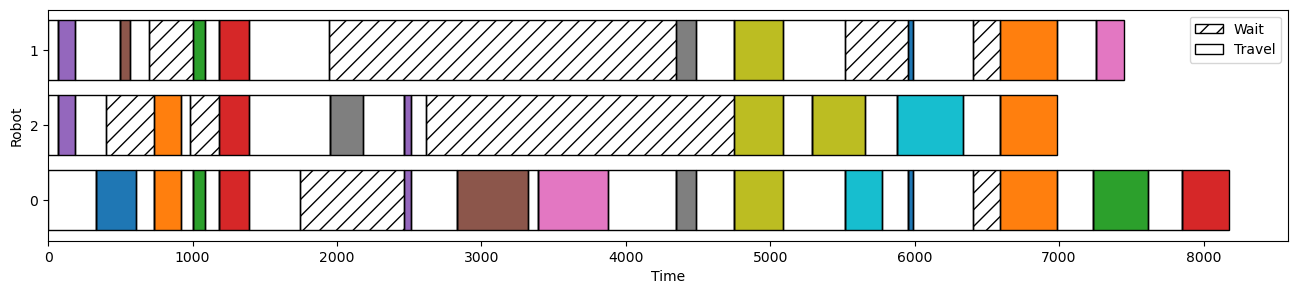

In [15]:
pdpcr_sol.plot_gantt_jp()

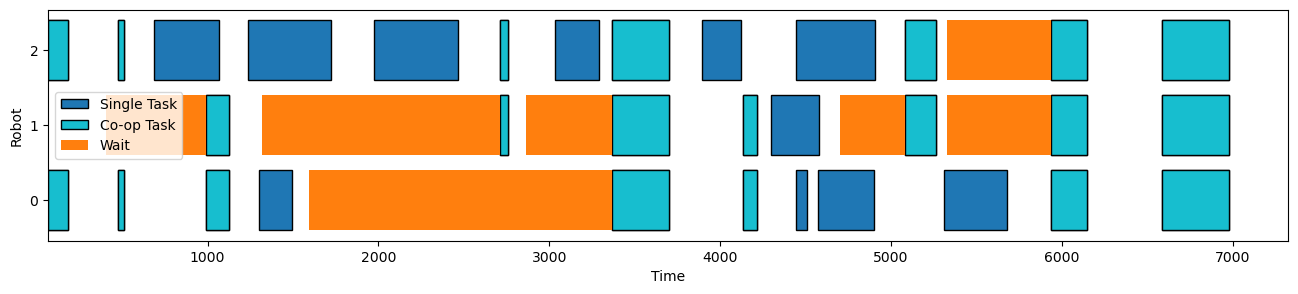

In [13]:
pdpcr_sol.plot_gantt_thao()

## Test true data

In [3]:
method = 5

total_robots = 3
random_data = False

data_type = 'csv'
data_name = 'generated18.csv'
# data_name = 'wr2/bar-n100-1-3.csv' #real data
# dist_path = 'wr2/bar-n100-1-dist.csv' #real data
total_tasks = 6 # random data

if False:
    is_depot_task = True
else:
    is_depot_task = False #TODO remove this
if random_data:
    raw = gen_data(total_robots, total_tasks, False, is_depot_task)
else:
    raw = get_data(data_name, data_type, is_depot_task)

print(f'Solving for {total_robots} robots and {len(raw.tasks)} tasks')
# processed_data = process(raw, method) 
# solve_result = solve_pdpcr(processed_data, total_robots, method,dist_path)

processed_h = heuristic.process_greedy_1(raw)
solve_result_h = heuristic.solve_greedy_1(processed_h, total_robots)
solve_result_h_jp = heuristic.solve_greedy_jp(processed_h, total_robots)

Solving for 3 robots and 10 tasks
Thao heuristics sol 2864.95
JP heuristics sol is 2897.7


In [10]:
idx_paths = [[task.index for task in solve_result_h.paths[k]] for k in range(total_robots)]
idx_paths = [path[1:-1] for path in idx_paths] #remove 0
idx_paths_jp = [[task.index for task in solve_result_h_jp.paths[k]] for k in range(total_robots)]
idx_paths_jp = [path[1:-1] for path in idx_paths_jp] #remove 0

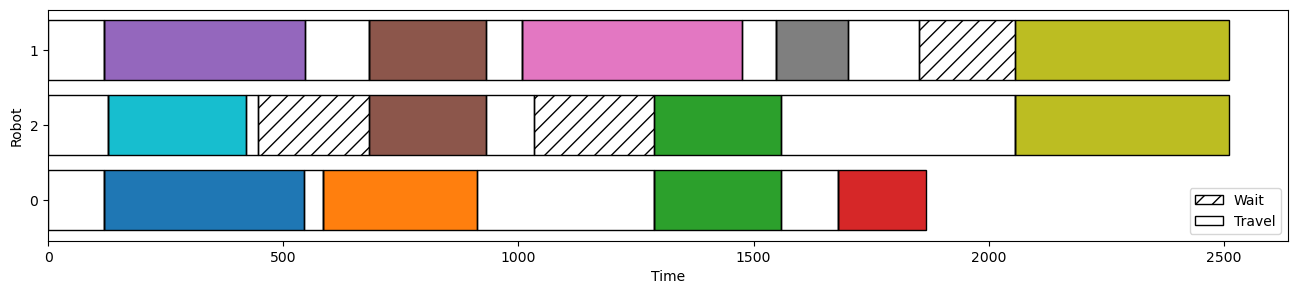

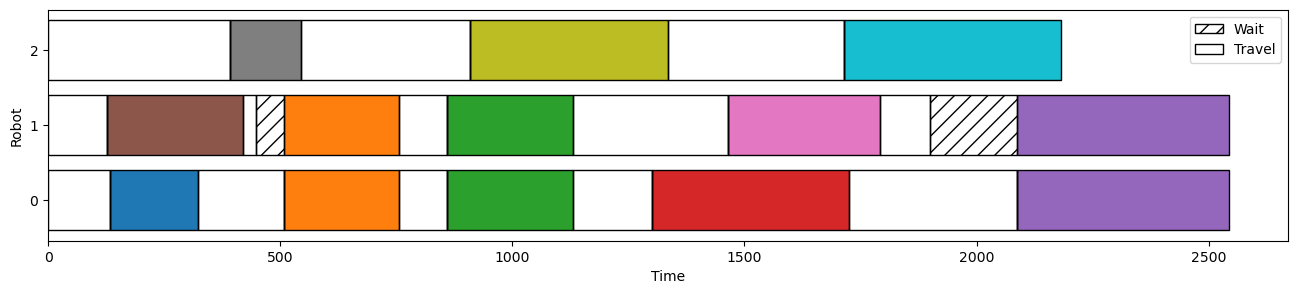

In [27]:
raw = get_data(data_name, data_type, True)
c_travel = helpers.create_task_dist_dict(raw.depot,raw.tasks)
c_operate = helpers.create_operate_dict(raw.depot,raw.tasks)

sol_thao = paths_to_sol(idx_paths,c_travel, c_operate)
pdpcr_sol_thao = PDPCR_Solution(idx_paths,sol_thao)
pdpcr_sol_thao.calculate(c_operate,c_travel)
pdpcr_sol_thao.to_df_sol(c_operate)
pdpcr_sol_thao.plot_gantt_jp()

sol_jp = paths_to_sol(idx_paths_jp,c_travel, c_operate)
pdpcr_sol_jp = PDPCR_Solution(idx_paths_jp,sol_jp)
pdpcr_sol_jp.calculate(c_operate,c_travel)
pdpcr_sol_jp.to_df_sol(c_operate)
pdpcr_sol_jp.plot_gantt_jp()
